# Tarea 3
**Integrantes**: Cristóbal Navarro y Cristopher Vasquez
### Instrucciones de uso
1. Tener la carpeta "BD" descomprimida en la misma carpeta donde se encuentra este ipynb.
2. Ejecutar celdas en orden.
### Instalación de librerías
Primero instalaremos todas las librerías necesarias para ejecutar el programa:

In [ ]:
%pip install numpy pandas matplotlib scikit-learn opencv-python scikit-image

Note: you may need to restart the kernel to use updated packages.


## Función para calculo de descriptores por canal
Hacemos una función capaz de sacar:
- Contraste
- Energia
- ASM
- Homogeneidad
- Correlación
- Disimilaridad

A esta función le enviaremos cada imagen con su respectivo canal RGB y en escala de grises.

In [ ]:
from skimage.feature import graycomatrix, graycoprops

def obtencionCaracteristicas (img):
    glcm = graycomatrix(img, distances=[1], angles=[0], levels=256, symmetric=True, normed=True)
    contraste = graycoprops(glcm, prop="contrast")[0,0]
    energia = graycoprops(glcm, prop= "energy")[0,0]
    ASM = graycoprops(glcm, prop = "ASM")[0,0]
    homogeneidad = graycoprops(glcm, prop= "homogeneity")[0,0]
    correlacion = graycoprops(glcm, prop= "correlation")[0,0]
    disimilaridad = graycoprops(glcm, prop= "dissimilarity")[0,0]
    
    return contraste, energia, ASM, homogeneidad, correlacion, disimilaridad 


### Extracción de Descriptores
Ya hecho esto definimos el path de la base de datos como `BD` y calculamos, para cada imagen, sus respectivos descriptores.
La imagen es separada por canal mediante la función `cv2.split()` y obtenemos el canal en escala de grises mediante `cv2.cvtColor(...,cv2.COLOR_BGR2GRAY)`.

In [ ]:
import cv2
import pandas as pd
from pathlib import Path
from collections import defaultdict

CARPETA = Path("BD")
Path("resultados").mkdir(exist_ok=True)

contador = defaultdict(int)
filas = []

for ruta in sorted(CARPETA.rglob("*.jpg")):
    img = cv2.imread(str(ruta))
    if img is None:
        print(f"No se pudo leer: {ruta}")
        continue

    clase = ruta.parent.name
    contador[clase] += 1
    img_id = f"{clase}_img{contador[clase]:02d}"

    azul, verde, rojo = cv2.split(img)
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    fila = {"id": img_id, "clase": clase}

    for nombre, canal in zip(("azul", "verde", "rojo", "gris"), (azul, verde, rojo, gris)):
        contraste, energia, ASM, homogeneidad, correlacion, disimilaridad = obtencionCaracteristicas(canal)

        fila[f"{nombre}_contraste"]     = contraste
        fila[f"{nombre}_energia"]       = energia
        fila[f"{nombre}_ASM"]           = ASM
        fila[f"{nombre}_homogeneidad"]  = homogeneidad
        fila[f"{nombre}_correlacion"]   = correlacion
        fila[f"{nombre}_disimilaridad"] = disimilaridad

    filas.append(fila)

df = pd.DataFrame(filas)

print(df[["id", "clase"]].head(10))
print(df.shape)

df.to_csv("resultados/Caracteristicas.csv", index=False)
print("\n Guardado en Caracteristicas.csv")

                 id       clase
0  textura_01_img01  textura_01
1  textura_01_img02  textura_01
2  textura_01_img03  textura_01
3  textura_01_img04  textura_01
4  textura_01_img05  textura_01
5  textura_01_img06  textura_01
6  textura_01_img07  textura_01
7  textura_01_img08  textura_01
8  textura_01_img09  textura_01
9  textura_01_img10  textura_01
(500, 26)

 Guardado en Caracteristicas.csv


### Normalización de Características
Ahora, con las características obtenidas, normalizaremos cada una de las columnas de características para obtener $\mu = 0$ y $\sigma = 1$.

In [ ]:
import pandas as pd

df = pd.read_csv("resultados/Caracteristicas.csv")

# Separar las 24 características de los identificadores y etiquetas.
X = df.drop(columns=["id", "clase"])

# Calcular los parámetros por columna.
medias = X.mean()
desviaciones = X.std(ddof=0)

# Normalizar. La sustitución evita dividir por cero en columnas constantes.
X_normalizado = (X - medias) / desviaciones.replace(0, 1)

# Verificar lo que pide la rúbrica.
verificacion = pd.DataFrame({
    "media": X_normalizado.mean(),
    "desviacion": X_normalizado.std(ddof=0)
})

display(verificacion.round(6))

# Conservar identificadores y clases sin modificarlos.
df_normalizado = df.copy()
df_normalizado[X.columns] = X_normalizado

df_normalizado.to_csv("resultados/Caracteristicas_normalizadas.csv", index=False)

,media,desviacion
azul_contraste,-0.0,1.0
azul_energia,0.0,1.0
azul_ASM,-0.0,1.0
azul_homogeneidad,0.0,1.0
azul_correlacion,-0.0,1.0
azul_disimilaridad,-0.0,1.0
verde_contraste,-0.0,1.0
verde_energia,0.0,1.0
verde_ASM,-0.0,1.0
verde_homogeneidad,-0.0,1.0


___
## Selección de Características mediante SFS e Índice de Fisher

Para reducir la dimensionalidad del conjunto de datos (24 características previamente normalizadas) y conservar únicamente las variables con mayor poder discriminante, se implementó el algoritmo **Sequential Forward Selection (SFS)**. A diferencia de una búsqueda exhaustiva —computacionalmente costosa al evaluar todas las combinaciones posibles—, SFS construye un ordenamiento de forma *greedy* (voraz) e iterativa, incorporando una característica por ciclo.

### 1. Preparación de etiquetas y agrupación por clase
A partir del archivo de características normalizadas, se separa la matriz numérica de atributos ($X_{\text{norm}}$) de los identificadores de imagen (`id`). Extrayendo el prefijo de cada identificador (por ejemplo, de `text1_img1` a `text1`), se construye el vector objetivo $y$, permitiendo agrupar las muestras según su clase de textura.

### 2. Criterio de evaluación: Índice de Fisher Multivariado ($J$)
Como función objetivo dentro de **SFS**, se maximiza el **Índice de Fisher multivariado ($J$)**, que cuantifica la relación entre la separación de las distintas clases y la dispersión interna de las muestras dentro de cada una:

$$J = \text{traza}\left(C_w^{-1} \cdot C_b\right)$$

Un valor alto de $J$ indica que las clases están bien separadas entre sí (alta varianza interclase) y que los datos de una misma textura son compactos (baja varianza intraclase). Las matrices se definen como:

- **Matriz de dispersión/covarianza intraclase ($C_w$):** mide la variabilidad interna promedio dentro de cada textura, ponderada por su probabilidad *a priori*:
$$C_w = \sum_{k=1}^{c} p_k \cdot \Sigma_k$$

- **Matriz de dispersión/covarianza interclase ($C_b$):** mide qué tan alejados están los centroides de cada clase respecto al centroide global de todos los datos:
$$C_b = \sum_{k=1}^{c} p_k (\bar{v}_k - \bar{v})(\bar{v}_k - \bar{v})^T$$

**Donde:**
- $c$: número total de clases (texturas).
- $p_k = \frac{N_k}{N}$: probabilidad *a priori* de la clase $k$ (proporción de imágenes de esa textura respecto al total $N$).
- $\Sigma_k$: matriz de covarianza poblacional de las muestras pertenecientes a la clase $k$.
- $\bar{v}_k$: vector promedio (centroide) de la clase $k$.
- $\bar{v}$: vector promedio global de todo el conjunto de datos.

### 3. Ejecución del algoritmo SFS y ganancia marginal ($\Delta J$)
El algoritmo recorre los 24 ciclos posibles hasta rankear la totalidad de las variables:
1. En cada ciclo $t$, se evalúan todas las características aún disponibles combinándolas con el subconjunto ya seleccionado.
2. Se incorpora aquella característica que maximiza el **Índice de Fisher acumulado ($J_t$)**.
3. Se registra la **mejora marginal ($\Delta J_t$)** respecto al ciclo anterior.

Evaluar el recorrido completo permite observar en qué punto el aporte de nuevas variables presenta rendimientos decrecientes ($\Delta J_t \approx 0$), facilitando identificar qué características aportan información redundante, además de poder elegir los 5 números de características de forma correcta, ya que podemos observar los puntos donde más alto es el índice de Fisher.

### 4. Resultados y visualización
Finalmente, el historial se consolida en una tabla de ranking (`df_resultado_sfs`) y se representa en dos gráficos complementarios:
- **Evolución acumulada de $J$:** muestra el crecimiento monotónico de la separabilidad entre clases a medida que aumenta la dimensionalidad.
- **Mejora marginal por ciclo ($\Delta J$):** permite detectar visualmente el "codo" o umbral óptimo de corte donde agregar más características deja de aportar ganancias significativas.

,Orden,Caracteristica,Indice_Fisher_J,Mejora_Respecto_Fisher_Anterior
0,1,verde_correlacion,7.439793,7.439793
1,2,gris_homogeneidad,12.768676,5.328883
2,3,rojo_homogeneidad,19.230140,6.461464
3,4,verde_energia,24.362324,5.132184
4,5,rojo_contraste,26.816513,2.454188
5,6,azul_contraste,30.095847,3.279335
6,7,azul_energia,33.593340,3.497492
7,8,verde_contraste,37.548011,3.954671
8,9,azul_homogeneidad,40.116931,2.568920
9,10,rojo_energia,42.206249,2.089318


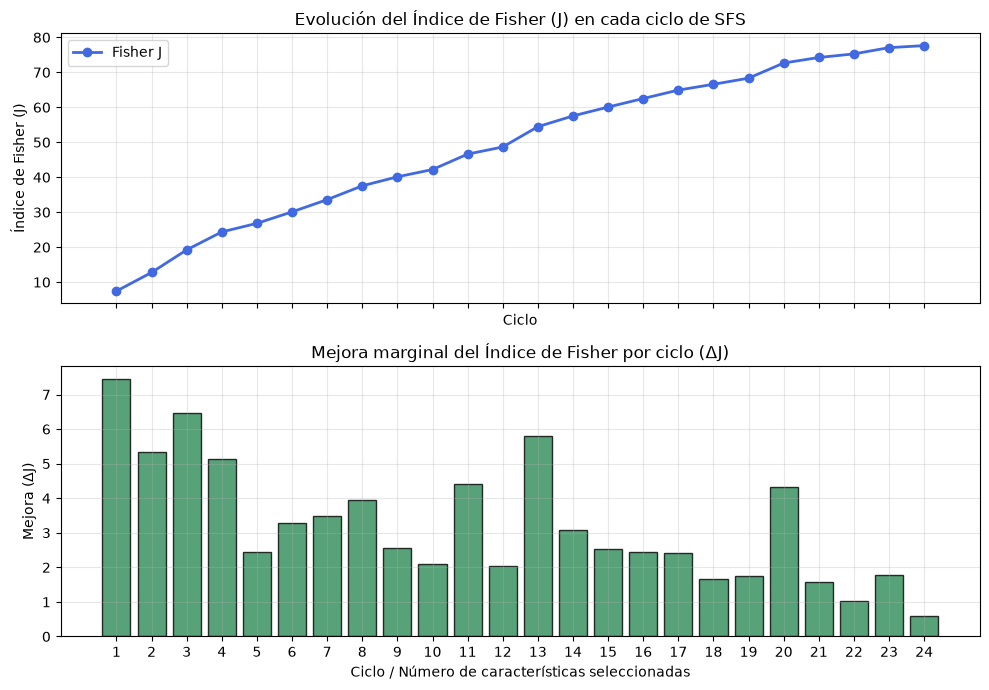

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#=== Cargamos el df normalizado ===
df_norm = pd.read_csv("resultados/Caracteristicas_normalizadas.csv")

# Separar etiquetas y características numéricas para el análisis descriptivo.
y = df_norm["clase"].to_numpy()
X_norm = df_norm.drop(columns=["id", "clase"])

#=== Creamos la funcion del indice de fisher ===
def indice_fisher(X_sub, y):
    #Cant. clases
    clases = np.unique(y)
    #Cant de imgs
    n_total = len(y)
    d = X_sub.shape[1]

    #Obtenemos el promedio de cada columna seleccionada
    media_global = np.mean(X_sub, axis=0)

    #Creamos las matrices con los tamaños de las columnas seleccionadas
    Cw = np.zeros((d, d))
    Cb = np.zeros((d, d))

    #Iteramos en las clases seleccionadas para ir calculando
    for k in clases:
        #Extraemos solo las filas de la clase k
        grupo = X_sub[y == k]

        # Proporción de muestras de esta textura en el conjunto recibido
        pk = len(grupo) / n_total
        #Media de la clase k
        media_k = np.mean(grupo, axis=0)
        
        # Matriz de covarianza intraclase (Cw)
        cov_k = np.atleast_2d(np.cov(grupo, rowvar=False, bias=True))
        Cw += pk * cov_k
        
        # Matriz de covarianza interclase (Cb)
        diff = (media_k - media_global).reshape(-1, 1)
        Cb += pk * (diff @ diff.T)

    # retornamos la traza de la multiplicación de Cb por la inversa de Cw obteniendo asi el indice de fisher
    return np.trace(np.linalg.inv(Cw) @ Cb)


#=== Algoritmo Sequential Forward Selection (SFS) ===

#Creamos listas donde guardaremos info importante
disponibles = list(X_norm.columns)
seleccionadas = []
historial = []
valores_fisher = []
mejoras_fisher = []   

for paso in range(1, len(disponibles) + 1):
    mejor_J = -np.inf
    mejor_feat = None

    #Recorremos las caracteristicas que no han sido elegidas 
    for caracteristica in disponibles:

        #Calculamos el indice con las caracteristicas que tenemos y la que queremos ingresar
        j_actual = indice_fisher(X_norm[seleccionadas + [caracteristica]].values, y)
        
        #Almacenamos la que mejor resultados nos de
        if j_actual > mejor_J:
            mejor_J = j_actual
            mejor_feat = caracteristica
            
    #Obtenemos cuanto mejoro el indice fisher en cada ciclo
    if paso == 1:
        mejora = mejor_J
    else:
        mejora = mejor_J-valores_fisher[-1]
        
    valores_fisher.append(mejor_J)
    mejoras_fisher.append(mejora)
    
    seleccionadas.append(mejor_feat)
    disponibles.remove(mejor_feat)
    historial.append({
        "Orden": paso,
        "Caracteristica": mejor_feat,
        "Indice_Fisher_J": mejor_J,
        "Mejora_Respecto_Fisher_Anterior": mejora   
    })

#Pasamos el historial a un dataframe para mostrarlo por la terminal
df_resultado_sfs = pd.DataFrame(historial)
display(df_resultado_sfs)


#=== Pasamos a un grafico los índices de fisher y mejoras obtenidas ===
ciclos = range(1, len(valores_fisher) + 1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Gráfico superior, Índice de Fisher acumulado
ax1.plot(ciclos, valores_fisher, marker="o", color="royalblue", linewidth=2, label="Fisher J")
ax1.set_title("Evolución del Índice de Fisher (J) en cada ciclo de SFS")
ax1.set_ylabel("Índice de Fisher (J)")
ax1.set_xlabel("Ciclo")
ax1.grid(alpha=0.3)
ax1.legend()

# Gráfico inferior, cuánto mejoró J en cada ciclo
ax2.bar(ciclos, mejoras_fisher, color="seagreen", edgecolor="black", alpha=0.8)
ax2.set_title("Mejora marginal del Índice de Fisher por ciclo (ΔJ)")
ax2.set_xlabel("Ciclo / Número de características seleccionadas")
ax2.set_ylabel("Mejora (ΔJ)")
ax2.set_xticks(ciclos)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

___
## Rendimiento del clasificador

Para evaluar la capacidad discriminante de los subconjuntos ordenados mediante SFS e Índice de Fisher, se entrenó un clasificador K-Nearest Neighbors (KNN con k=7) utilizando validación cruzada estratificada de 5 particiones **(100 imagenes por partición)**.  
A partir de la tabla y el gráfico de rendimiento se observa que:

1. Con las primeras 6 características (Top 6) el modelo alcanza un **accuracy promedio de 88,2%**, demostrando que las primeras variables seleccionadas por el Índice de Fisher concentran la mayor parte de la **separabilidad** entre las 10 clases de textura.
   
2. Su desviación estándar($\sigma$) de 0,039192 indica una variabilidad aproximada de
3,92 puntos porcentuales entre particiones, superior a la obtenida con
24 características. Por ello, la elección prioriza la reducción de
dimensionalidad y el rendimiento promedio, reconociendo una menor
consistencia entre particiones.

1. Entre 10 y 15 características el desempeño no mejora e incluso desciende hasta **85,2%**, lo que puede significar que incorporar descriptores de menor aporte introduce **redundancia y ruido** en el cálculo de distancias euclidianas del clasificador.

2. Al utilizar las 24 características, el accuracy llega a **87,6%**, representando una perdida de **0,6** puntos porcentuales respecto al subconjunto de 6 características.

Con lo anterior descrito, se usarán 6 características como el número óptimo de ellas, ya que alcanza el mayor accuracy promedio entre los tamaños evaluados para KNN con 7 vecinos, reduciendo la dimensionalidad un 75 %, aunque presente mayor variabilidad que el conjunto completo.

,Subconjunto,Num_Caracteristicas,Accuracy_Promedio,Desviacion_Std
0,Top 5,5,0.870,0.037947
1,Top 6,6,0.882,0.039192
2,Top 10,10,0.852,0.029257
3,Top 11,11,0.852,0.029257
4,Top 15,15,0.858,0.027129
5,Top 16,16,0.852,0.027857
6,Top 20,20,0.876,0.024166
7,Top 21,21,0.874,0.028705
8,Top 24,24,0.876,0.021541


Número de características elegido: 6
Mejor accuracy promedio: 88.2%


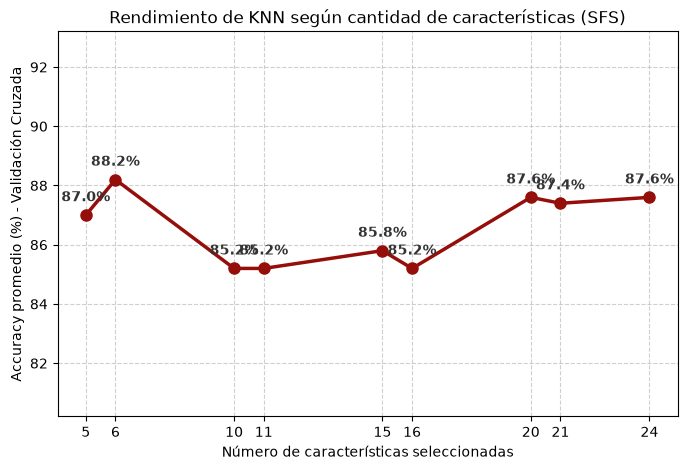

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier


def orden_sfs(X_train, y_train):
    """Ordenar las columnas por Fisher usando solo el conjunto recibido."""
    elegidas = []
    disponibles = list(range(X_train.shape[1]))

    while disponibles:
        mejor = max(
            disponibles,
            key=lambda j: indice_fisher(
                X_train[:, elegidas + [j]], y_train
            )
        )
        elegidas.append(mejor)
        disponibles.remove(mejor)

    return elegidas


# Partir de los datos originales: normalizar dentro de cada partición.
datos = pd.read_csv("resultados/Caracteristicas.csv")
X = datos.drop(columns=["id", "clase"])
y = datos["clase"].to_numpy()

tamanos_k = [5,6,10,11,15,16,20,21,24]
validacionC = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
registros = []

for fold, (idx_train, idx_val) in enumerate(
    validacionC.split(X, y), start=1
):
    # Aprender la normalización solo con las 400 imágenes de entrenamiento.
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X.iloc[idx_train])
    X_val = scaler.transform(X.iloc[idx_val])
    y_train = y[idx_train]
    y_val = y[idx_val]

    # La selección tampoco utiliza las imágenes ni etiquetas de validación.
    orden = orden_sfs(X_train, y_train)

    for k in tamanos_k:  
        columnas = orden[:k]
        modelo = KNeighborsClassifier(n_neighbors=7, metric="euclidean")
        modelo.fit(X_train[:, columnas], y_train)
        accuracy = modelo.score(X_val[:, columnas], y_val)

        registros.append({
            "Fold": fold,
            "Num_Caracteristicas": k,
            "Accuracy": accuracy,
        })

resultados_cv = pd.DataFrame(registros)
df_resultados = resultados_cv.groupby(
    "Num_Caracteristicas", as_index=False
).agg(
    Accuracy_Promedio=("Accuracy", "mean"),
    Desviacion_Std=("Accuracy", lambda s: s.std(ddof=0)),
)
# Identificar los subconjuntos evaluados; su composición puede variar por fold.
df_resultados.insert(
    0, "Subconjunto",
    "Top " + df_resultados["Num_Caracteristicas"].astype(str)
)
display(df_resultados)

# En caso de empate, elegir el menor tamaño entre los evaluados.
mejor_accuracy = df_resultados["Accuracy_Promedio"].max()
k_elegido = int(
    df_resultados.loc[
        np.isclose(df_resultados["Accuracy_Promedio"], mejor_accuracy),
        "Num_Caracteristicas"
    ].min()
)
print("Número de características elegido:", k_elegido)
print(f"Mejor accuracy promedio: {100 * mejor_accuracy:.1f}%")

# Gráfico del accuracy promedio según el número de características
plt.figure(figsize=(8, 5))

# Convertimos a porcentaje (0 a 100) para leerlo más fácil
acc_pct = df_resultados["Accuracy_Promedio"] * 100

plt.plot(
    df_resultados["Num_Caracteristicas"],
    acc_pct,
    marker="o",
    markersize=8,
    linestyle="-",
    linewidth=2.5,
    color="#950e09",
)

# Escribimos el porcentaje exacto encima de cada punto
for x_val, y_val in zip(df_resultados["Num_Caracteristicas"], acc_pct):
    plt.annotate(
        f"{y_val:.1f}%",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontweight="bold",
        color="#333333",
    )

plt.xticks(tamanos_k)
plt.ylim(acc_pct.min() - 5, min(100, acc_pct.max() + 5))
plt.xlabel("Número de características seleccionadas")
plt.ylabel("Accuracy promedio (%) - Validación Cruzada")
plt.title("Rendimiento de KNN según cantidad de características (SFS)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

##  Cuantización Vectorial (VQ)

Una vez elegido el subcojunto de 6 características mediante SFS y la evaluación del clasificador KNN, se aplica **VQ**, utilizando **K-means** sobre las características normalizadas.

Primero almacenamos las características elegidas:

In [ ]:
# Ajuste definitivo para VQ, después de evaluar los tamaños por validación.
scaler_final = StandardScaler()
X_final_norm = scaler_final.fit_transform(X)
orden_final = orden_sfs(X_final_norm, y)
columnas_finales = X.columns[orden_final[:k_elegido]].tolist()

print("Características elegidas para VQ:")
for nombre in columnas_finales:
    print("-", nombre)


Características elegidas para VQ:
- verde_correlacion
- gris_homogeneidad
- rojo_homogeneidad
- verde_energia
- rojo_contraste
- azul_contraste


Se utiliza K-means con **100 grupos** como se indicó en la tarea. Cada grupo será representado por un centroide calculado como el promedio de las muestras asignadas a él.

De esta manera, la matriz pasa de** 500x6 a 100x6**, lo que representa una reducción del 80% del numero de *muestras*, distinto a minimizar la cantidad de *caracteristicas* seleccionadas, lo cual diferencia a ambos.

Se grafican los tres pares posibles entre las primeras tres
características del ranking final de SFS:

- Correlación del canal verde.
- Homogeneidad de la imagen en escala de grises.
- Homogeneidad del canal rojo.

Tanto en 2D como finalmente en 3D (porque nos daba curiosidad).

Dimensiones iniciales: (500, 6)
Dimensiones comprimidas: (100, 6)
Reducción de muestras: 80.0%


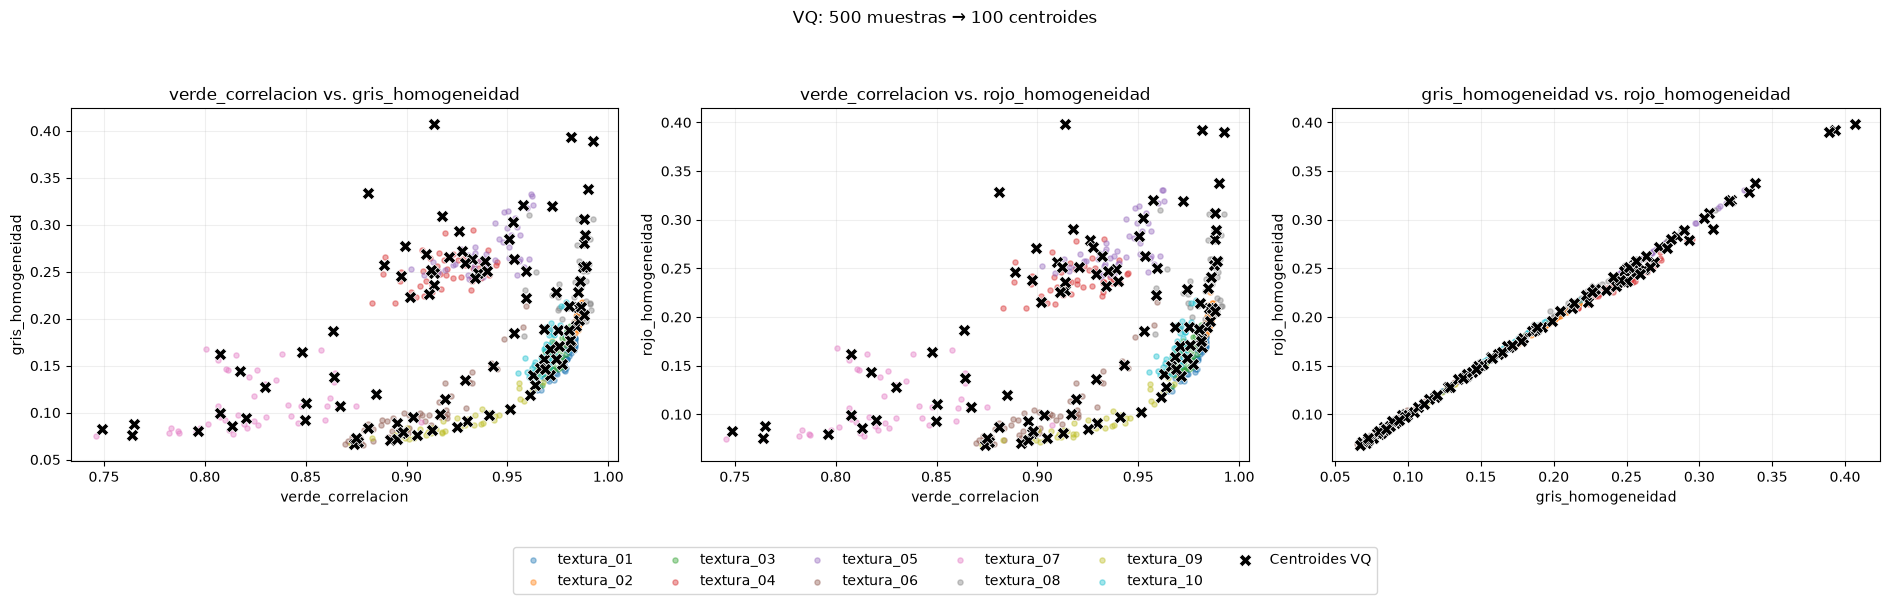

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.cluster import KMeans

# Leer ambos archivos y asegurar el mismo orden de imágenes.
originales = pd.read_csv(
    "resultados/Caracteristicas.csv"
).set_index("id")

normalizadas = pd.read_csv(
    "resultados/Caracteristicas_normalizadas.csv"
).set_index("id").loc[originales.index]

columnas_vq = columnas_finales.copy()

X_vq = normalizadas[columnas_vq]
X_original = originales[columnas_vq]

# Obtener las etiquetas para colorear las muestras.
y_vq = originales["clase"]

# VQ mediante K-means: 500 muestras -> 100 representantes.
n_centroides = 100

vq = KMeans(
    n_clusters=n_centroides,
    n_init=10,
    random_state=42,
)
vq.fit(X_vq)

centroides_norm = pd.DataFrame(
    vq.cluster_centers_,
    columns=columnas_vq,
)

print("Dimensiones iniciales:", X_vq.shape)
print("Dimensiones comprimidas:", centroides_norm.shape)
print(
    "Reducción de muestras:",
    f"{100 * (1 - n_centroides / len(X_vq)):.1f}%"
)

# Deshacer el z-score con los parámetros de la parte II. (Volver a la escala original de las características)
medias_vq = X_original.mean()
desviaciones_vq = X_original.std(ddof=0).replace(0, 1)

centroides = centroides_norm * desviaciones_vq + medias_vq

# Graficar pares de las primeras tres características del SFS.
# El agrupamiento utiliza todas las elegidas; los gráficos son proyecciones 2D.
pares = list(combinations(columnas_vq[:3], 2))
fig, axes = plt.subplots(1, len(pares), figsize=(19, 6))
colores = plt.get_cmap("tab10")

for ax, (a, b) in zip(axes, pares):
    for i, clase in enumerate(sorted(y_vq.unique())):
        mascara = y_vq == clase

        ax.scatter(
            X_original.loc[mascara, a],
            X_original.loc[mascara, b],
            color=colores(i),
            s=14,
            alpha=0.4,
            label=clase,
        )

    ax.scatter(
        centroides[a],
        centroides[b],
        marker="X",
        s=80,
        c="black",
        edgecolors="white",
        linewidths=0.5,
        label="Centroides VQ",
        zorder=3,
    )

    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs. {b}")
    ax.grid(alpha=0.2)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6)
fig.suptitle("VQ: 500 muestras → 100 centroides")
plt.tight_layout(rect=(0, 0.13, 1, 0.93))
plt.show()

Grafico 3D extra ya que nos interesaba verlo.

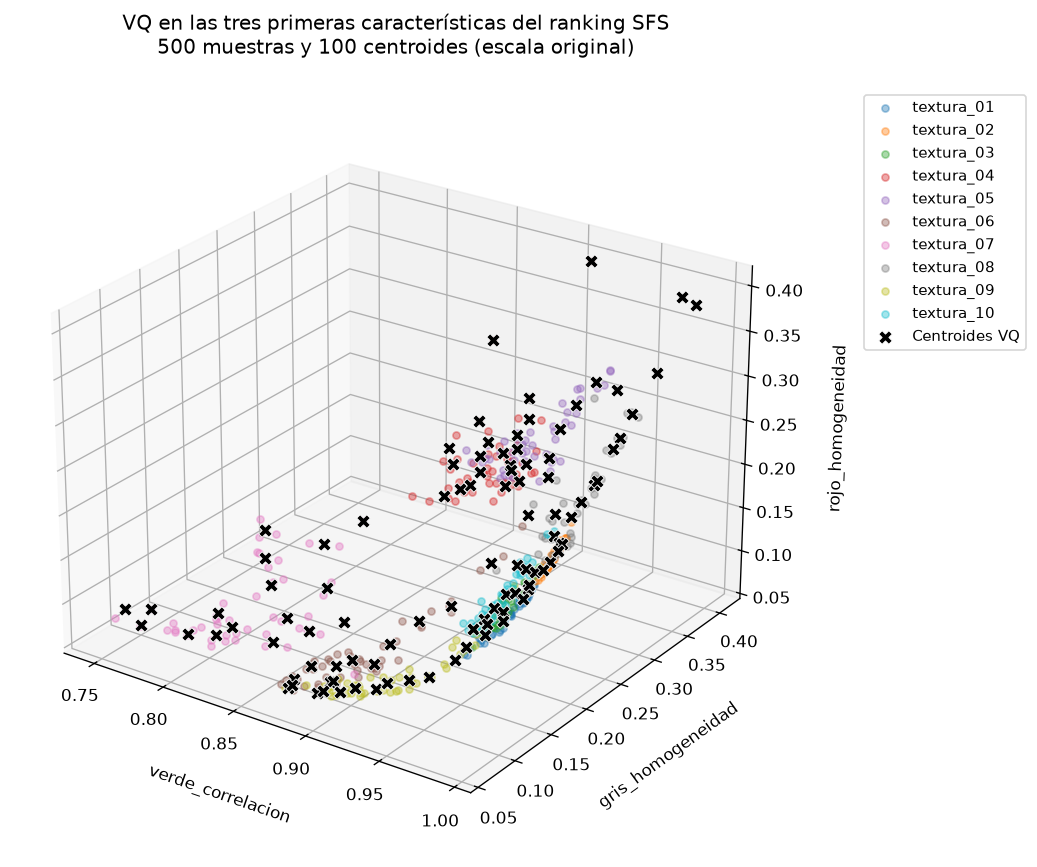

In [ ]:
import matplotlib.pyplot as plt

# Proyección 3D
eje_x, eje_y, eje_z = columnas_vq[:3]
fig_3d = plt.figure(figsize=(12, 8))
ax_3d = fig_3d.add_subplot(111, projection="3d", computed_zorder=False)
colores_3d = plt.get_cmap("tab10")

for i, clase in enumerate(sorted(y_vq.unique())):
    mascara = y_vq == clase
    ax_3d.scatter(
        X_original.loc[mascara, eje_x],
        X_original.loc[mascara, eje_y],
        X_original.loc[mascara, eje_z],
        color=colores_3d(i),
        s=18,
        alpha=0.4,
        depthshade=False,
        label=clase,
        zorder=1,
    )

ax_3d.scatter(
    centroides[eje_x],
    centroides[eje_y],
    centroides[eje_z],
    marker="X",
    s=65,
    c="black",
    edgecolors="white",
    linewidths=0.5,
    depthshade=False,
    label="Centroides VQ",
    zorder=2,
)

ax_3d.set_xlabel(eje_x, labelpad=12)
ax_3d.set_ylabel(eje_y, labelpad=12)
ax_3d.set_zlabel(eje_z, labelpad=12)
ax_3d.set_title(
    f"VQ en las tres primeras características del ranking SFS\n"
    f"{len(X_original)} muestras y {len(centroides)} centroides (escala original)",
    pad=20,
)
ax_3d.view_init(elev=25, azim=-55)
ax_3d.legend(loc="upper left", bbox_to_anchor=(1.10, 1.0), fontsize=9)
fig_3d.subplots_adjust(left=0.02, right=0.76, bottom=0.08, top=0.88)
plt.show()


## Conclusiones
Ambas etapas cumplen sus funciones, SFS reduce el número de características, mientras que VQ reduce el número de muestras. 

Los resultados nos muestran que mediante la selección de caracteristicas, podemos tener una mejor base para un entrenamiento menos pesado de distintos modelos, lo cual la hace un area bastante interesante desde nuestra perspectiva.

Gracias por leer.

### Referencias

1. https://scikit--image-org.translate.goog/docs/stable/auto_examples/features_detection/plot_glcm.html?_x_tr_sl=en&_x_tr_tl=es&_x_tr_hl=es&_x_tr_pto=sge

2. https://scikit--image-org.translate.goog/docs/stable/api/skimage.feature.html?_x_tr_sl=en&_x_tr_tl=es&_x_tr_hl=es&_x_tr_pto=tc#skimage.feature.graycoprops